# Q2D | Train Linear Regression

> Train a Linear Regression model using the training data with four-fold cross-validation and with appropriate evaluation metric. Do this with a closed-form solution (using the Normal Equation or SVD) and with SGD. Then focus on SGD and perform Ridge, Lasso and Elastic Net regularization – try three values of penalty term and describe its impact. Explore the impact of other hyperparameters of your choice, such as learning rate (no need for grid search). Describe your findings. Select the best-performing regularization set of hyperparameters and train that model on the entire training dataset. For SGD, display the training and validation loss as a function of training epochs for the selected model. (Hint: In scikit-learn, max_iter counts epochs (full passes over the training set). To plot training/validation loss by epoch with SGDRegressor, set max_iter=1 and warm_start=True, then call fit(...) in a loop; after each call (each epoch), compute and record Train and Validation RMSE). Ensure reproducibility by using a seed.

**IMPORTANT**

This notebook uses only the train dataset (the first 584 days), so no modeling decision is influenced by the test data (data snooping). Every score below is a cross validation score on the training rows.

# Answer Summary

**Cross validation and metric**
- Four time-ordered folds: each trains on every day before its 46-day validation block, scored by RMSE in rentals per day.
- Each choice starts from the simpler option, which another replaces only if its mean validation RMSE is at least 1% lower.

**Features**
- Fixed shapes from Q2B and Q2C on 9 attributes.

**Closed form vs SGD**
- The closed form (SVD) cuts Dummy's error by about two thirds: 823.3 against 2521.6.
- SGD at scikit-learn's defaults lands within 4 rentals of it: 827.1.

**Other hyperparameters**
- `eta0`: steps of 0.001 and below stop far short; 0.1 is only 0.46% better than the default 0.01, which is kept.
- Schedule: the default `invscaling` is kept; `adaptive` is only 0.40% better, `constant` is 1.67% worse and `optimal` diverges.

**Regularization**
- Every penalty costs, even at alpha 0.001.
- L1 bites first: at alpha 0.1 Lasso rises to 1289.5 against 937.0 for Ridge.
- A strong penalty underfits: at alpha 10 training and validation RMSE rise together.
- No penalty helps because the gap between training and validation RMSE is a shift in time, not overfitting: Dummy, which cannot overfit, shows it too.
- The target is standardized so `alpha` means the same in Q1 and Q2: on rentals per day, Lasso at alpha 0.1 would barely penalize (823.1 against 1289.5).

**Selected model**
- Ridge at alpha 0.001 (`invscaling`, `eta0` 0.01), picked as required, at a small cost: 828.1 against 827.1 without a penalty.
- Trained on all 584 days and saved: training RMSE 635.4.

**Loss by epoch**
- Training RMSE settles in 3 epochs; validation RMSE keeps falling until about epoch 10 and never turns up, so more epochs do not overfit.
- The homework's loop restarts the step at 0.01 every epoch; here it learns faster and ends slightly lower (824.9 against 828.1), but it is not how the selected model trained.

**Reproducibility**
- Seed 42 for every SGD model; the folds are fixed by date and need none.

---

# Imports

In [1]:
import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer

import Q2.consts as Q2_CONSTS
from consts import TEST_SIZE, CV_SPLITS, SEED, CARRY_MARGIN, MAX_ITER, TOL, POWER_T, LEARNING_RATE_SCHEDULES, ETA0S, ALPHAS, L1_RATIO

from utils import (
	read_csv_to_df,
	SPLIT,
	STATISTICS,
	PLOTTING,
	PIPELINES,
)

pd.set_option('display.max_rows', None)
pd.set_option('display.min_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.1f}'.format)  # rentals; a diverging run would otherwise switch a whole table to 1e+12 style

# Fetch Data

In [2]:
df = read_csv_to_df(path=Q2_CONSTS.DATA_PATH, parse_dates=["dteday"])
df = df.rename(columns=Q2_CONSTS.SHORT_NAMES)
train_df, _ = SPLIT.chronological_split(df=df, date_col="Date", test_size=TEST_SIZE)

ATTRIBUTES = ['Temp', 'FeelsLike', 'Humidity', 'Wind', 'Year', 'IsHoliday', 'IsWorkday', 'Season', 'Month', 'Weekday', 'Weather']
X, y = train_df[ATTRIBUTES], train_df[Q2_CONSTS.TARGET]
print(f"left out: {', '.join(column for column in train_df.columns if column not in ATTRIBUTES + [Q2_CONSTS.TARGET])}")

left out: ID, Date, Casual, Registered


# Setup

## Folds

In [3]:
# Each fold trains on every day before its validation block of 46 days, the way the model will predict the test days
# after the training days. The 4 blocks are the last 184 training days.
FOLDS = list(TimeSeriesSplit(n_splits=CV_SPLITS, test_size=Q2_CONSTS.CV_TEST_SIZE).split(X))

pd.DataFrame({
	'training rows': [len(train) for train, _ in FOLDS],
	'first validation day': [f"{train_df['Date'].iloc[validation[0]]:%Y-%m-%d}" for _, validation in FOLDS],
	'last validation day': [f"{train_df['Date'].iloc[validation[-1]]:%Y-%m-%d}" for _, validation in FOLDS],
}, index=pd.RangeIndex(1, len(FOLDS) + 1, name='fold'))

,training rows,first validation day,last validation day
fold,,,
1,400,2012-02-05,2012-03-21
2,446,2012-03-22,2012-05-06
3,492,2012-05-07,2012-06-21
4,538,2012-06-22,2012-08-06


## Features

| Attribute | Shape | Source |
|---|---|---|
| `FeelsLike` | cap at 0.573 (`'cap'`) | Q2B |
| `Temp` | dropped | Q2C: r 0.997 with `FeelsLike` |
| `Humidity` | hinge at 0.699, the one 0.0 day clipped up to 0.172 | Q2B's hinge; it beat Q2B's floor in earlier experiments |
| `Wind` | raw | Q2B |
| `Weather` | the code as a number | Q2B |
| `Year` | raw | Q2B keeps it in every model |
| `Season` | 3 groups, {1} \| {2, 4} \| {3} (`'3 groups'`) | Q2B, fit with `Year` |
| `Month` | the code as a number | Q2B's hinge only tied the code in earlier experiments |
| `Weekday`, `IsHoliday` | raw | putting them back helped in earlier experiments |
| `IsWorkday` | dropped | with `Weekday` and `IsHoliday` in, dropping it lowered RMSE in earlier experiments |

In [4]:
FITS = {attribute: STATISTICS.shape_fits(df=train_df, feature=attribute, target=Q2_CONSTS.TARGET) for attribute in Q2_CONSTS.CONTINUOUS}
FITS['Season'] = STATISTICS.category_fits(df=train_df, feature='Season', target=Q2_CONSTS.TARGET, control='Year')

def shape(*, attribute, name):
	"""Q2B's shape of an attribute by name (ex 'cap'), with the setting Q2B found, as a pipeline step."""
	return next(fit for fit in FITS[attribute] if fit.name == name).transformer

HUMIDITY_CLIPPED_HINGE = make_pipeline(FunctionTransformer(np.clip, kw_args={'a_min': 0.172, 'a_max': None}), shape(attribute='Humidity', name='hinge'))

SHAPES = {
	'Temp': 'drop',  # Q2C: r 0.997 with FeelsLike
	'FeelsLike': shape(attribute='FeelsLike', name='cap'),  # Q2B
	'Humidity': HUMIDITY_CLIPPED_HINGE,  # Q2B's hinge; it beat Q2B's floor in earlier experiments
	'Wind': 'passthrough',  # Q2B
	'Year': 'passthrough',  # Q2B keeps it in every model
	'IsHoliday': 'passthrough',  # putting it back helped in earlier experiments
	'IsWorkday': 'drop',  # with Weekday and IsHoliday in, dropping it lowered RMSE in earlier experiments
	'Season': shape(attribute='Season', name='3 groups'),  # Q2B, fit with Year
	'Month': 'passthrough',  # the code as a number: Q2B's hinge only tied it in earlier experiments
	'Weekday': 'passthrough',  # putting it back helped in earlier experiments
	'Weather': 'passthrough',  # the code as a number, Q2B
}

## Runs

In [5]:
RUNS = {}  # every cross validation result, keyed by name

def build(*, model):
	"""The pipeline of one experiment: shapes, standardized columns, model (see PIPELINES.build_pipeline)."""
	return PIPELINES.build_pipeline(model=model, attributes=ATTRIBUTES, shapes=SHAPES)

def score(*, name, pipeline, folds=FOLDS):
	"""Cross validate a pipeline and keep its result under name."""
	RUNS[name] = PIPELINES.cv_rmse(pipeline=pipeline, X=X, y=y, folds=folds)

def table(*, names, baseline=None):
	"""One row per run in names: mean validation RMSE, mean training RMSE, the most epochs for SGD, and the change from
	the baseline when one is given."""
	return STATISTICS.results_df(runs={name: RUNS[name] for name in names}, decimals=1, baseline=baseline)

def lowest(*, names):
	"""The run in names with the lowest mean validation RMSE."""
	return min(names, key=lambda name: RUNS[name]['validation rmse'].mean())

def carried(*, baseline, names):
	"""The decision rule: the run in names with the lowest mean validation RMSE replaces the baseline (the simpler
	option) only if it is at least CARRY_MARGIN (1%) lower; otherwise the baseline is kept."""
	best = lowest(names=names)
	gain = 1 - RUNS[best]['validation rmse'].mean() / RUNS[baseline]['validation rmse'].mean()
	return best if gain >= CARRY_MARGIN else baseline

# Method

- **Metric:** RMSE in rentals per day. `validation rmse` is the mean over the 4 folds of the RMSE on each fold's validation days, days the model never saw; every choice is made on it. `train rmse` is the same on the days each model was fit on.
- **Folds:** four time-ordered folds (`TimeSeriesSplit`): each trains on every day before its 46-day validation block.
- **Why 46 days:** it carries over an earlier setup of 6 folds of 31 days (about a month each, the last 186 training days) to the 4 folds the homework asks for: 186 / 4 is about 46. It meets the one hard limit: the 4 blocks together (184 days) must fit inside the 219 days of 2012 in train, so that every fold trains on some 2012 days and can learn `Year`; the first fold still trains on 35 of them. Against a shorter block (ex 30 days, about a month), 46 validates over more of the year (February to August instead of April to August), bases each fold's score on more days, and predicts further ahead, closer to the 147 days of the test set. The cost is that the first fold sees fewer 2012 days.
- **Rule:** each choice starts from a baseline, the simpler option: scikit-learn's default `eta0` (0.01) and schedule (`invscaling`). The option with the lowest mean validation RMSE replaces the baseline only if it is at least 1% lower (`CARRY_MARGIN`); a smaller gain is not worth the added step. The `% vs baseline` column shows the change. The selected regularized model has no baseline: the lowest mean wins.
- **Pipeline:** shapes, standardized columns, model. The target is standardized too, and the predictions come back in rentals per day (Why the Target Is Standardized, below, shows what this changes). Every step is fit on the training days of a fold only.
- **Closed form:** least squares solved by SVD (`PIPELINES.SVDRegression`, numpy's `lstsq`).
- **Seed:** seed 42 for every SGD model. The folds need none: `TimeSeriesSplit` has no randomness, it always cuts the same blocks by date. Dummy and SVD are deterministic.
- **Optimism:** every choice is made on these folds, and Q2B's shape settings were found on all training days, so the scores are a little optimistic. The test set gives the honest estimate.

# Baselines

Dummy predicts the training mean; the closed form is least squares by SVD on the features.

In [6]:
score(name='Dummy', pipeline=build(model=DummyRegressor()))  # predicts the training mean of every fold
score(name='Closed form', pipeline=build(model=PIPELINES.SVDRegression()))  # least squares on the features, solved by SVD

table(names=['Dummy', 'Closed form'])

,validation rmse,train rmse
Dummy,2521.6,1476.3
Closed form,823.3,584.2


### Notes / Observations

- **The features cut Dummy's error by about two thirds:** the closed form scores 823.3 against 2521.6.
- **The gap between training and validation RMSE is a shift in time, not overfitting:** Dummy, which cannot overfit, shows it too (1476.3 against 2521.6), since each fold validates on days after the ones it trained on.

# SGD

`SGDRegressor` on the features, starting from scikit-learn's defaults with every setting written out: `penalty=None` (the default is a light L2 penalty), the learning rate schedule, `eta0`, `power_t`, `max_iter` and `tol`. `max_iter` is only a ceiling: a fit stops once its training loss improves by less than `tol` for 5 epochs in a row.

In [7]:
CLOSED_FORM = 'Closed form'  # the closed form SGD is compared against
SGD_SETTINGS = dict(penalty=None, learning_rate='invscaling', eta0=0.01, power_t=POWER_T, max_iter=MAX_ITER, tol=TOL, random_state=SEED)  # scikit-learn's defaults, written out
SETTINGS = {}  # the settings of every SGD run, keyed by name
YMAX = 1.1 * RUNS['Dummy']['validation rmse'].mean()  # a run that diverges is drawn at the top of a chart instead of flattening the rest

def sgd(*, name, settings):
	"""Cross validate SGD with these settings on the features, and keep the settings under name."""
	SETTINGS[name] = settings
	score(name=name, pipeline=build(model=SGDRegressor(**settings)))

## SGD vs Closed Form

In [8]:
sgd(name='SGD', settings=SGD_SETTINGS)

table(names=[CLOSED_FORM, 'SGD'])

,validation rmse,train rmse,most epochs
Closed form,823.3,584.2,<NA>
SGD,827.1,584.6,11


### Notes / Observations

- **At scikit-learn's defaults SGD lands within 4 rentals of the closed form:** 827.1 against 823.3, after at most 11 epochs.

## Learning Rate (eta0)

`eta0` is the starting step: under `invscaling` the step shrinks from it as training goes on. It is tried at 5 values, with the schedule at its default, and the default 0.01 is the baseline (rule in Method).

,validation rmse,train rmse,most epochs,% vs baseline
Closed form,823.3,584.2,<NA>,-0.46%
eta0=1e-05,2512.4,1466.8,8,+203.74%
eta0=0.0001,1952.7,992.5,117,+136.08%
eta0=0.001,1098.1,624.2,43,+32.76%
eta0=0.01,827.1,584.6,11,baseline
eta0=0.1,823.3,601.6,18,-0.46%


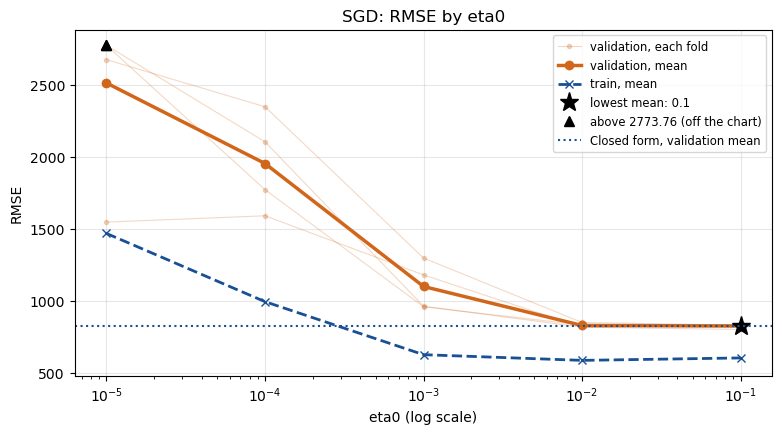

In [9]:
names = {eta0: f'eta0={eta0}' for eta0 in ETA0S}
for eta0, name in names.items():
	sgd(name=name, settings={**SGD_SETTINGS, 'eta0': eta0})
baseline = names[SGD_SETTINGS['eta0']]  # scikit-learn's default, 0.01

display(table(names=[CLOSED_FORM, *names.values()], baseline=baseline))
PLOTTING.parameter_search(
	runs={eta0: RUNS[name] for eta0, name in names.items()},
	parameter='eta0',
	log_x=True,
	reference=(CLOSED_FORM, RUNS[CLOSED_FORM]),
	ymax=YMAX,
	title='SGD: RMSE by eta0',
)
SGD_SETTINGS = {**SGD_SETTINGS, 'eta0': SETTINGS[carried(baseline=baseline, names=names.values())]['eta0']}

### Notes / Observations

- **The default 0.01 is kept:** 0.1 is the only value that does better, and only by 0.46%, under the 1% the rule asks for.
- **Small steps stop far short:** at 0.001 and below SGD stays above 1,000 (1098.1 at 0.001).

## Learning Rate Schedule

How the step changes from `eta0` as training goes on, at the carried `eta0`; `invscaling`, the default, is the baseline (rule in Method).

- `constant`: the step stays `eta0`.
- `optimal`: sets its own step from `alpha` and ignores `eta0`.
- `invscaling`: the step is `eta0 / t ** power_t`, shrinking as training goes on.
- `adaptive`: keeps `eta0` and divides it by 5 each time the training loss stalls for 5 epochs.

In [10]:
names = {schedule: f'learning_rate={schedule}' for schedule in LEARNING_RATE_SCHEDULES}
for schedule, name in names.items():
	sgd(name=name, settings={**SGD_SETTINGS, 'learning_rate': schedule})
baseline = names[SGD_SETTINGS['learning_rate']]  # scikit-learn's default, invscaling

display(table(names=[CLOSED_FORM, *names.values()], baseline=baseline))
SGD_SETTINGS = {**SGD_SETTINGS, 'learning_rate': SETTINGS[carried(baseline=baseline, names=names.values())]['learning_rate']}
display(pd.Series(SGD_SETTINGS, name='carried').astype(str).to_frame())  # as text: the 1 decimal float format would show power_t 0.25 as 0.2 and tol 0.001 as 0.0

,validation rmse,train rmse,most epochs,% vs baseline
Closed form,823.3,584.2,<NA>,-0.46%
learning_rate=constant,841.0,601.4,11,+1.67%
learning_rate=optimal,836756105336772.0,869488702102169.0,154,> +999%
learning_rate=invscaling,827.1,584.6,11,baseline
learning_rate=adaptive,823.8,584.2,44,-0.40%


,carried
penalty,None
learning_rate,invscaling
eta0,0.01
power_t,0.25
max_iter,10000
tol,0.001
random_state,42


### Notes / Observations

- **`invscaling`, the default, is kept:** `adaptive` is 0.40% lower, by training 4 times longer (44 epochs against 11), under the 1% the rule asks for.
- **A step that never shrinks does worse:** `constant` is 1.67% higher, and `optimal`, which ignores `eta0`, diverges.

# Regularization

The carried SGD with a penalty: Ridge (`l2`), Lasso (`l1`) and Elastic Net (`elasticnet`, with `l1_ratio` fixed at 0.5, an even mix of both). `alpha`, the penalty's strength, is tried at 3 values a hundred times apart. Every run is compared with the same SGD without a penalty.

,validation rmse,train rmse,most epochs
No penalty,827.1,584.6,11
"Ridge, alpha=0.001",828.1,584.6,11
"Ridge, alpha=0.1",937.0,598.9,12
"Ridge, alpha=10",2385.8,1337.8,10
"Lasso, alpha=0.001",829.9,584.7,11
"Lasso, alpha=0.1",1289.5,720.4,15
"Lasso, alpha=10",2523.9,1476.3,6
"Elastic Net, alpha=0.001",829.0,584.6,11
"Elastic Net, alpha=0.1",1121.2,650.8,15
"Elastic Net, alpha=10",2523.9,1476.3,6


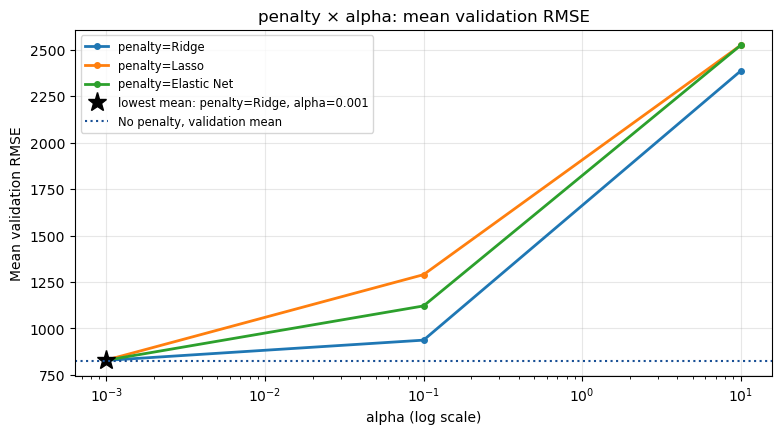

In [11]:
PENALTIES = {'Ridge': 'l2', 'Lasso': 'l1', 'Elastic Net': 'elasticnet'}
sgd(name='No penalty', settings=SGD_SETTINGS)

REGULARIZED = {(label, alpha): f'{label}, alpha={alpha}' for label in PENALTIES for alpha in ALPHAS}
for (label, alpha), name in REGULARIZED.items():
	sgd(name=name, settings={**SGD_SETTINGS, 'penalty': PENALTIES[label], 'alpha': alpha, **({'l1_ratio': L1_RATIO} if label == 'Elastic Net' else {})})

display(table(names=['No penalty', *REGULARIZED.values()]))
PLOTTING.parameter_cross(
	runs={pair: RUNS[name] for pair, name in REGULARIZED.items()},
	lines='penalty',
	x='alpha',
	log_x=True,
	reference=('No penalty', RUNS['No penalty']),
	ymax=YMAX,
);

### Notes / Observations

- **Every penalty costs:** even at alpha 0.001 none beats no penalty (827.1).
- **L1 bites first:** at alpha 0.1 Lasso rises to 1289.5 against 937.0 for Ridge; Elastic Net lands between them.
- **A strong penalty underfits:** at alpha 10 Ridge's training and validation RMSE rise together (1337.8 and 2385.8), and Lasso and Elastic Net predict the mean (2523.9).

## Why the Target Is Standardized

Every pipeline in this notebook standardizes `Rentals` before the model sees it: it subtracts the mean of the training days and divides by their standard deviation, and the predictions are converted back to rentals per day before they are scored. Every RMSE in this notebook is in rentals per day.

This is a change of units, not of shape: the target's distribution looks exactly the same, only the numbers on its axis change. So it has nothing to do with skew or outliers, and it fixes neither. What a change of units does to each model:
- **Closed form and Dummy:** nothing. Least squares gives the same predictions in any units.
- **SGD without a penalty, and Ridge:** almost nothing. Each SGD step is proportional to the error, and so are the coefficients it is heading for, so SGD takes the same path in any units. Only `tol` differs: it is a fixed number compared with the training loss, and the loss grows with the square of the units, so a fit can stop (or `adaptive` can cut its step) a few epochs earlier or later.
- **Lasso and Elastic Net:** what `alpha` means. The L1 penalty pulls every coefficient toward 0 by the same amount on every step, whatever the target's units. So the larger the target's standard deviation, the larger the coefficients and the less the same `alpha` touches them; on a standardized target the standard deviation is 1.

So the target is standardized to put `alpha` and `tol` on the same scale in Q1 and Q2, which share the lists in `consts.py`. The table refits four of this notebook's models without it.

In [12]:
# build(...).regressor is the same pipeline without the target scaler: the model fits and predicts the target in its own units
CHECKS = {  # label: (the run with the target standardized, its model)
	'Closed form': (CLOSED_FORM, PIPELINES.SVDRegression()),
	'SGD, no penalty': ('No penalty', SGDRegressor(**SETTINGS['No penalty'])),
	'Ridge, alpha=0.1': ('Ridge, alpha=0.1', SGDRegressor(**SETTINGS['Ridge, alpha=0.1'])),
	'Lasso, alpha=0.1': ('Lasso, alpha=0.1', SGDRegressor(**SETTINGS['Lasso, alpha=0.1'])),
}
for label, (_, model) in CHECKS.items():
	score(name=f'{label}, target not standardized', pipeline=build(model=model).regressor)

display(pd.Series({'mean': y.mean(), 'standard deviation': y.std()}, name=f'{Q2_CONSTS.TARGET}, training days').to_frame())
pd.DataFrame({
	'target standardized': [RUNS[name]['validation rmse'].mean() for name, _ in CHECKS.values()],
	'target not standardized': [RUNS[f'{label}, target not standardized']['validation rmse'].mean() for label in CHECKS],
}, index=pd.Index(list(CHECKS), name='mean validation rmse'))

,"Rentals, training days"
mean,4153.6
standard deviation,1788.9


,target standardized,target not standardized
mean validation rmse,,
Closed form,823.3,823.3
"SGD, no penalty",827.1,822.9
"Ridge, alpha=0.1",937.0,936.8
"Lasso, alpha=0.1",1289.5,823.1


### Notes / Observations

- **The closed form is identical both ways (823.3):** least squares gives the same predictions in any units.
- **SGD and Ridge barely move:** SGD without a penalty lands 4 rentals lower (822.9 against 827.1), the small difference `tol` can make.
- **Lasso changes completely:** at the same alpha 0.1 it scores 1289.5 on the standardized target and 823.1 on rentals per day. In rentals the coefficients are large (the target's standard deviation is 1788.9), so the same L1 pull hardly touches them and Lasso scores like no penalty.
- **This is why the target is standardized:** without it, the `alpha` values in `consts.py` would barely penalize this notebook's Lasso and Elastic Net at all.

# Selected Model

The homework asks for one regularized model, so the 9 regularized runs are ranked by mean validation RMSE and the lowest is selected.

When no penalty improves on the model without one, the smallest `alpha` tends to win, because it changes the model the least. The selected model is then close to the model without a penalty: it is picked because the homework requires a regularized one, not because the penalty helps.

In [13]:
SELECTED = lowest(names=REGULARIZED.values())
display(pd.Series(SETTINGS[SELECTED], name=SELECTED).astype(str).to_frame())  # as text: the 1 decimal float format would show a small alpha as 0.0

table(names=['No penalty', SELECTED])

,"Ridge, alpha=0.001"
penalty,l2
learning_rate,invscaling
eta0,0.01
power_t,0.25
max_iter,10000
tol,0.001
random_state,42
alpha,0.001


,validation rmse,train rmse,most epochs
No penalty,827.1,584.6,11
"Ridge, alpha=0.001",828.1,584.6,11


### Notes / Observations

- **Ridge at alpha 0.001 is picked as required, at a small cost:** 828.1 against 827.1 without a penalty, the smallest alpha, as explained above.

## Train on the Entire Training Set

The selected model refit once, with no folds, on all 584 training days, and saved. The saved pipeline takes the 11 raw attributes and builds its own columns.

In [14]:
final = build(model=SGDRegressor(**SETTINGS[SELECTED])).fit(X, y)
Q2_CONSTS.MODEL_OUTPUT_DIR.mkdir(exist_ok=True)
joblib.dump(final, Q2_CONSTS.MODEL_OUTPUT_DIR / 'linear_regression.joblib')

pd.Series({
	'training rows': len(X),
	'epochs run': PIPELINES.final_model(pipeline=final).n_iter_,
	'train rmse': mean_squared_error(y, final.predict(X), squared=False),
}, dtype=object).to_frame(SELECTED)  # object: keeps the counts whole numbers

,"Ridge, alpha=0.001"
training rows,584
epochs run,8
train rmse,635.4


### Notes / Observations

- **Training RMSE on all 584 days is above the folds' (635.4 against 584.6), but the fit is sound:** it stops after 8 epochs (the folds took at most 11), and it also trains on the last validation block, days no fold trains on.

## Training and Validation Loss by Epoch

**What the chart is for:** following training and validation RMSE epoch by epoch, to see when training settles and whether more epochs start to overfit (validation RMSE turning up while training RMSE keeps falling). Each chart shows the selected model on every fold, for as many epochs as it ran on its longest fold.

**Two ways to draw it:**
- **The homework's loop:** a copy of the selected model with `max_iter=1` and `warm_start=True`, fit once per epoch on each fold's training days, recording training and validation RMSE after each `fit` call.
- **The exact curve:** epoch k is a fresh fit of the selected model with `max_iter=k` and the same seed, which is exactly the first k epochs of its real training. A fold's line goes flat once `tol` stops it.

**Why they differ:** `warm_start=True` carries only the coefficients from one `fit` call to the next. Everything else starts over:

| | One long fit (how the selected model trained) | The homework's loop (one `fit` call per epoch) |
|---|---|---|
| Coefficients | carry on | carry on (`warm_start=True`) |
| Step under `constant` | `eta0` | `eta0`, the same |
| Step under `invscaling` (`eta0 / t ** power_t`, `t` counts the days seen) | keeps shrinking | starts again at `eta0` every epoch: `fit` sets `t` back to 1 |
| Step under `adaptive` (divided by 5 after 5 epochs without improvement) | shrinks after each stall | stays at `eta0`: a 1-epoch fit can never stall 5 times |
| Order the days are visited in | a new shuffle every epoch | the same shuffle every epoch: each `fit` starts from the seed |

So the loop replays the real training only under `constant`, and even then it visits the days in one fixed order. Under the other schedules it trains a different model: one whose step never gets smaller than where a single epoch leaves it. The exact curve shows how the selected model trained; the loop is drawn because the homework asks for it.

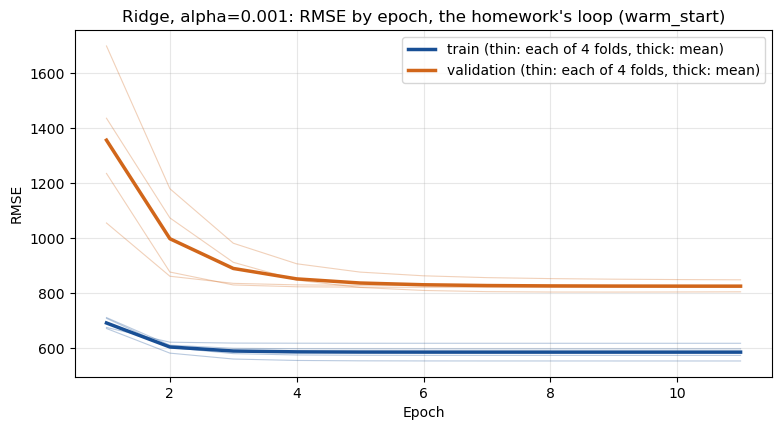

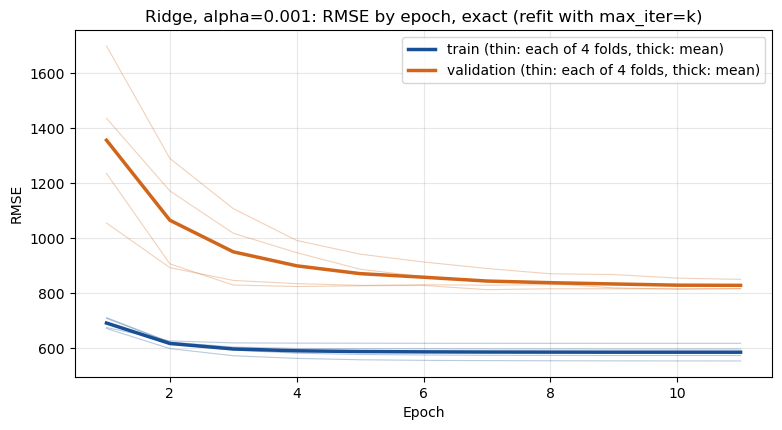

In [15]:
EPOCHS = int(RUNS[SELECTED]['epochs'].max())  # as many epochs as the selected model ran on its longest fold
pipeline = build(model=SGDRegressor(**SETTINGS[SELECTED]))
CURVES = {
	method: PIPELINES.epoch_rmse(pipeline=pipeline, X=X, y=y, folds=FOLDS, epochs=EPOCHS, method=method)
	for method in ('warm_start', 'refit')
}
for method, label in (('warm_start', "the homework's loop (warm_start)"), ('refit', 'exact (refit with max_iter=k)')):
	PLOTTING.loss_curve(curve=CURVES[method], title=f'{SELECTED}: RMSE by epoch, {label}', ymax=YMAX);

### Notes / Observations

- **Training RMSE settles in 3 epochs, validation RMSE keeps falling until about epoch 10:** what the later epochs change barely matters on the training days but still helps on the later validation days.
- **More epochs do not overfit:** validation RMSE never turns up and ends at its lowest.

### The Two Curves Side by Side

The mean of the folds for both curves on one chart, and the scores each ends on. The exact curve's last epoch is each fold's full fit, so it ends on the selected model's cross validation score from the Selected Model table; the homework's loop does not.

,validation rmse,train rmse
cross validation (Selected Model),828.1,584.6
"homework's loop, last epoch",824.9,584.7
"exact curve, last epoch",828.1,584.6


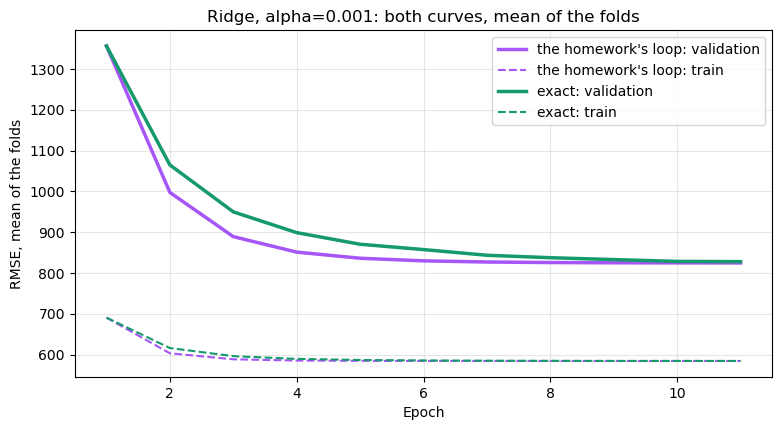

In [16]:
PLOTTING.loss_curve_comparison(curves=CURVES, title=f'{SELECTED}: both curves, mean of the folds', ymax=YMAX);
pd.DataFrame({
	'cross validation (Selected Model)': RUNS[SELECTED][['validation rmse', 'train rmse']].mean(),
	"homework's loop, last epoch": CURVES['warm_start'].xs(EPOCHS, level='epoch').mean(),
	'exact curve, last epoch': CURVES['refit'].xs(EPOCHS, level='epoch').mean(),
}).T[['validation rmse', 'train rmse']]

### Notes / Observations

- **The two curves start together and part at epoch 2:** from epoch 2 the loop restarts `invscaling`'s step at 0.01, while the long fit's step keeps shrinking.
- **Here the loop learns faster and ends slightly lower:** its larger steps cut validation RMSE sooner, and it ends at 824.9 against 828.1. Both have settled by the last epoch.
- **The loop is still a different model:** only the exact curve ends on the selected model's cross validation score (828.1), so it is the one that shows how the selected model trained.